# XNIDS: Explainable, Risk-Prioritized Network Intrusion Detection

End-to-end pipeline on **CICIDS2017** (Canadian Institute for Cybersecurity, UNB):

1. Load and clean the eight daily flow files
2. Data-quality audit (duplicates, malformed flows) and a cleaned "v2" dataset
3. Baselines: binary (benign vs. DDoS) and 12-class Random Forest
4. Grouped web attacks, imbalance handling (class weights, SMOTE), model comparison
5. Cross-day validation (does the model generalise to a benign day it never saw?)
6. Risk-based alert prioritisation (confidence x attack severity x service criticality)
7. SHAP explanations for the highest-priority alerts

This notebook and `xnids.py` contain **identical code**. The notebook is generated from the
script by `tools/sync_notebook.py`, so edit the `.py` file and re-run that tool.

Set `XNIDS_FAST=1` for a quick smoke test on a small sample of the data.

In [1]:
# Setup and imports
import gc
import json
import os
import platform
import re
import sys
import time
import warnings
from contextlib import contextmanager
from pathlib import Path

import matplotlib

if "ipykernel" not in sys.modules:
    matplotlib.use("Agg")  # script mode: save figures to disk instead of opening windows
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

try:
    from IPython.display import display
except ImportError:  # plain script without IPython
    display = print

try:
    import shap
except ImportError:
    shap = None
try:
    from imblearn.over_sampling import SMOTE
except ImportError:
    SMOTE = None

warnings.filterwarnings("ignore", message=".*non-interactive.*")
warnings.filterwarnings("ignore", category=FutureWarning)

In [2]:
# Configuration
RANDOM_STATE = 42
FAST = os.environ.get("XNIDS_FAST", "0") == "1"  # quick smoke-test mode
_per_file = os.environ.get("XNIDS_BENIGN_PER_FILE")  # sampled mode: cap benign flows per file at load time
DATA_DIR = Path(os.environ.get("XNIDS_DATA_DIR", "data"))
OUT_DIR = Path(os.environ.get("XNIDS_OUT_DIR", "reports/quick" if FAST else ("reports/sampled" if _per_file else "reports")))
FIG_DIR = OUT_DIR / "figures"
MODEL_DIR = Path("models")  # git-ignored
for _d in (OUT_DIR, FIG_DIR, MODEL_DIR):
    _d.mkdir(parents=True, exist_ok=True)

N_TREES = 40 if FAST else 100  # trees per Random Forest
BENIGN_PER_FILE = int(_per_file) if _per_file else (25_000 if FAST else None)
BENIGN_CAP = 40_000 if FAST else 300_000  # benign cap for the "capped" experiments (sections 7-11)
RARE_MIN = 50  # classes with fewer flows than this are dropped from multi-class training
SMOTE_TARGET = 5_000  # oversample minority classes up to this many training flows

# Short names for the eight CICIDS2017 files (lower-case file stem -> source name)
EXPECTED_FILES = {
    "monday-workinghours": "Monday",
    "tuesday-workinghours": "Tuesday",
    "wednesday-workinghours": "Wednesday",
    "thursday-workinghours-morning-webattacks": "Thu-AM-WebAttacks",
    "thursday-workinghours-afternoon-infilteration": "Thu-PM-Infiltration",
    "friday-workinghours-morning": "Fri-AM-Bot",
    "friday-workinghours-afternoon-portscan": "Fri-PM-PortScan",
    "friday-workinghours-afternoon-ddos": "Fri-PM-DDoS",
}
SOURCES = list(EXPECTED_FILES.values())

RESULTS = {"config": {"fast": FAST, "n_trees": N_TREES, "benign_cap": BENIGN_CAP, "benign_per_file": BENIGN_PER_FILE}, "experiments": {}, "timings": {}, "data_quality": {}}
print(f"FAST mode: {FAST} | data: {DATA_DIR} | output: {OUT_DIR}")

FAST mode: False | data: data | output: reports


In [3]:
# Helper functions
@contextmanager
def timed(label):
    """Time a block and record it (used as scalability evidence in the report)."""
    start = time.perf_counter()
    yield
    RESULTS["timings"][label] = round(time.perf_counter() - start, 2)
    print(f"  [{label}] {RESULTS['timings'][label]:.1f}s")


def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close("all")


def evaluate(name, y_true, y_pred, show_report=True):
    """Store accuracy / macro-F1 / weighted-F1 / per-class F1 and optionally print the report."""
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    labels = sorted(set(y_true) | set(y_pred))
    rep = classification_report(y_true, y_pred, labels=labels, output_dict=True, zero_division=0)
    RESULTS["experiments"][name] = {
        "n_test": int(len(y_true)),
        "accuracy": round(rep["accuracy"], 5),
        "macro_f1": round(rep["macro avg"]["f1-score"], 5),
        "weighted_f1": round(rep["weighted avg"]["f1-score"], 5),
        "macro_recall": round(rep["macro avg"]["recall"], 5),
        "per_class_f1": {str(lab): round(rep[str(lab)]["f1-score"], 4) for lab in labels},
    }
    if show_report:
        print(f"\n=== {name} ===")
        print(classification_report(y_true, y_pred, labels=labels, digits=3, zero_division=0))
    return RESULTS["experiments"][name]


def plot_confusion(name, y_true, y_pred, title):
    """Row-normalised confusion matrix (each row = share of that true class)."""
    labels = sorted(set(np.asarray(y_true)) | set(np.asarray(y_pred)))
    cm = confusion_matrix(y_true, y_pred, labels=labels, normalize="true") * 100
    plt.figure(figsize=(max(6, 0.75 * len(labels)), max(5, 0.65 * len(labels))))
    sns.heatmap(cm, annot=True, fmt=".0f", cmap="Blues", xticklabels=labels, yticklabels=labels, cbar_kws={"label": "% of true class"})
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(title)
    save_fig(name)


def make_rf(**kwargs):
    return RandomForestClassifier(n_estimators=N_TREES, random_state=RANDOM_STATE, n_jobs=-1, **kwargs)


def cap_benign(X, y, cap, seed=RANDOM_STATE):
    """Keep every attack flow but at most `cap` benign flows (stratified-by-class subsample)."""
    is_benign = (y == "BENIGN").to_numpy()
    benign_idx = np.flatnonzero(is_benign)
    keep_benign = np.random.default_rng(seed).choice(benign_idx, size=min(cap, len(benign_idx)), replace=False)
    keep = np.sort(np.concatenate([np.flatnonzero(~is_benign), keep_benign]))
    return X.iloc[keep], y.iloc[keep]

## 1. Load and clean the data
Each file is cleaned as it is loaded:
- column names have stray whitespace (a known CICIDS2017 quirk) -> stripped
- the web-attack labels contain a corrupted dash character -> normalised to `-`
- infinite values (divide-by-zero in rate features) and NaNs -> rows dropped
- features are stored as `float32` to roughly halve memory use

A `Source` column records which day/file each flow came from (used for cross-day validation).

In [4]:
# Load all eight files
def clean_labels(series):
    return series.astype(str).str.replace(r"[^\x00-\x7F]+", "-", regex=True).str.strip()


def load_file(path, source):
    df = pd.read_csv(path, encoding="latin-1", low_memory=False)
    df.columns = df.columns.str.strip()
    df["Label"] = clean_labels(df["Label"])
    df = df.replace([np.inf, -np.inf], np.nan).dropna()
    features = df.columns.drop("Label")
    df[features] = df[features].astype("float32")
    if BENIGN_PER_FILE is not None:  # sampled / FAST mode only
        benign = df["Label"] == "BENIGN"
        if benign.sum() > BENIGN_PER_FILE:
            df = pd.concat([df[benign].sample(BENIGN_PER_FILE, random_state=RANDOM_STATE), df[~benign]])
    df["Source"] = pd.Categorical([source] * len(df), categories=SOURCES)
    return df.reset_index(drop=True)


files = {}
for p in sorted(DATA_DIR.glob("*.csv")):
    key = p.name.split(".pcap")[0].lower()
    if key in EXPECTED_FILES:
        files[EXPECTED_FILES[key]] = p
missing = [s for s in SOURCES if s not in files]
if missing:
    raise FileNotFoundError(f"Missing CICIDS2017 files for {missing} in {DATA_DIR.resolve()}. See the README for download steps.")

frames = {}
with timed("load_and_clean"):
    for source in SOURCES:
        frames[source] = load_file(files[source], source)
        print(f"  {source:<20} {len(frames[source]):>9,} flows")

full_v1 = pd.concat(frames.values(), ignore_index=True)
del frames  # free ~1 GB; everything below works from full_v1 (its Source column identifies the file)
gc.collect()
FEATURES = [c for c in full_v1.columns if c not in ("Label", "Source")]
print(f"\nCombined (v1): {full_v1.shape[0]:,} flows, {len(FEATURES)} features")
print(full_v1["Label"].value_counts().to_string())

  Monday                 529,481 flows


  Tuesday                445,645 flows


  Wednesday              691,406 flows


  Thu-AM-WebAttacks      170,231 flows


  Thu-PM-Infiltration    288,395 flows


  Fri-AM-Bot             190,911 flows


  Fri-PM-PortScan        286,096 flows


  Fri-PM-DDoS            225,711 flows
  [load_and_clean] 30.9s



Combined (v1): 2,827,876 flows, 78 features
Label
BENIGN                        2271320
DoS Hulk                       230124
PortScan                       158804
DDoS                           128025
DoS GoldenEye                   10293
FTP-Patator                      7935
SSH-Patator                      5897
DoS slowloris                    5796
DoS Slowhttptest                 5499
Bot                              1956
Web Attack - Brute Force         1507
Web Attack - XSS                  652
Infiltration                       36
Web Attack - Sql Injection         21
Heartbleed                         11


## 2. Data-quality audit
CICIDS2017 is known to contain exact duplicate flows, malformed flows (negative durations) and one
duplicated column. Duplicates matter for ML: if the same flow lands in both the training and test split,
the test score is inflated. This section measures each issue and builds a cleaned **v2** dataset.

In [5]:
# Audit and build the cleaned v2 dataset
DUP_COLS = ["Fwd Header Length.1"] if "Fwd Header Length.1" in FEATURES and full_v1["Fwd Header Length"].equals(full_v1["Fwd Header Length.1"]) else []
dup_mask = full_v1.duplicated(subset=FEATURES + ["Label"])
neg_mask = full_v1["Flow Duration"] < 0
RESULTS["data_quality"] = {
    "rows_after_inf_nan_removal": int(len(full_v1)),
    "exact_duplicate_rows": int(dup_mask.sum()),
    "duplicate_share_pct": round(100 * dup_mask.mean(), 2),
    "negative_flow_duration_rows": int(neg_mask.sum()),
    "identical_duplicate_columns": DUP_COLS,
}
print(json.dumps(RESULTS["data_quality"], indent=2))

full_v2 = full_v1[~dup_mask & ~neg_mask].drop(columns=DUP_COLS).reset_index(drop=True)
FEATURES_V2 = [c for c in FEATURES if c not in DUP_COLS]
RESULTS["data_quality"]["rows_v2"] = int(len(full_v2))
print(f"\nv2 (deduplicated, malformed flows removed): {len(full_v2):,} flows")
dq_counts = pd.DataFrame({"v1": full_v1["Label"].value_counts(), "v2": full_v2["Label"].value_counts()}).fillna(0).astype(int)
dq_counts["removed_pct"] = (100 * (1 - dq_counts["v2"] / dq_counts["v1"])).round(1)
display(dq_counts)
dq_counts.to_csv(OUT_DIR / "label_counts_v1_vs_v2.csv")

{
  "rows_after_inf_nan_removal": 2827876,
  "exact_duplicate_rows": 329896,
  "duplicate_share_pct": 11.67,
  "negative_flow_duration_rows": 115,
  "identical_duplicate_columns": [
    "Fwd Header Length.1"
  ]
}



v2 (deduplicated, malformed flows removed): 2,497,873 flows


,v1,v2,removed_pct
Label,,,
BENIGN,2271320,2072147,8.8
Bot,1956,1948,0.4
DDoS,128025,128014,0.0
DoS GoldenEye,10293,10282,0.1
DoS Hulk,230124,172846,24.9
DoS Slowhttptest,5499,5228,4.9
DoS slowloris,5796,5374,7.3
FTP-Patator,7935,5931,25.3
Heartbleed,11,11,0.0


## 3. Baseline models (reproduces the Week 1-2 results)
**Binary:** Monday (benign only) + Friday DDoS file, benign vs. attack.
**Multi-class (v1):** all files, the three rarest classes removed, default Random Forest.

In [6]:
# Binary baseline: benign vs. DDoS
binary = full_v1[full_v1["Source"].isin(["Monday", "Fri-PM-DDoS"])].reset_index(drop=True)
y_bin = (binary["Label"] != "BENIGN").astype(int)
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(binary[FEATURES], y_bin, test_size=0.2, random_state=RANDOM_STATE, stratify=y_bin)
with timed("rf_binary_fit"):
    rf_bin = make_rf().fit(Xb_tr, yb_tr)
evaluate("binary_benign_vs_ddos", yb_te, rf_bin.predict(Xb_te))
top_bin = pd.Series(rf_bin.feature_importances_, index=FEATURES).nlargest(10)
print("Top binary features:\n", top_bin.round(4).to_string())
del binary, Xb_tr, Xb_te, rf_bin
gc.collect()

  [rf_binary_fit] 54.2s



=== binary_benign_vs_ddos ===
              precision    recall  f1-score   support

           0      1.000     1.000     1.000    125434
           1      1.000     1.000     1.000     25605

    accuracy                          1.000    151039
   macro avg      1.000     1.000     1.000    151039
weighted avg      1.000     1.000     1.000    151039

Top binary features:
 Avg Bwd Segment Size      0.0808
Bwd Packet Length Max     0.0788
Average Packet Size       0.0570
Max Packet Length         0.0514
Packet Length Variance    0.0505
Bwd Packet Length Std     0.0501
Fwd Packet Length Max     0.0453
Packet Length Std         0.0401
Subflow Fwd Bytes         0.0350
Bwd Packet Length Mean    0.0338


92

  [rf_multiclass_v1_fit] 526.6s



=== multiclass_v1_baseline ===


                          precision    recall  f1-score   support

                  BENIGN      0.999     0.999     0.999    454264
                     Bot      0.901     0.765     0.827       391
                    DDoS      1.000     1.000     1.000     25605
           DoS GoldenEye      0.997     0.993     0.995      2059
                DoS Hulk      0.998     0.999     0.999     46025
        DoS Slowhttptest      0.991     0.992     0.991      1100
           DoS slowloris      0.997     0.998     0.998      1159
             FTP-Patator      1.000     0.998     0.999      1587
                PortScan      0.994     0.996     0.995     31761
             SSH-Patator      1.000     0.999     1.000      1180
Web Attack - Brute Force      0.732     0.791     0.760       301
        Web Attack - XSS      0.413     0.331     0.368       130

                accuracy                          0.999    565562
               macro avg      0.919     0.905     0.911    565562
        

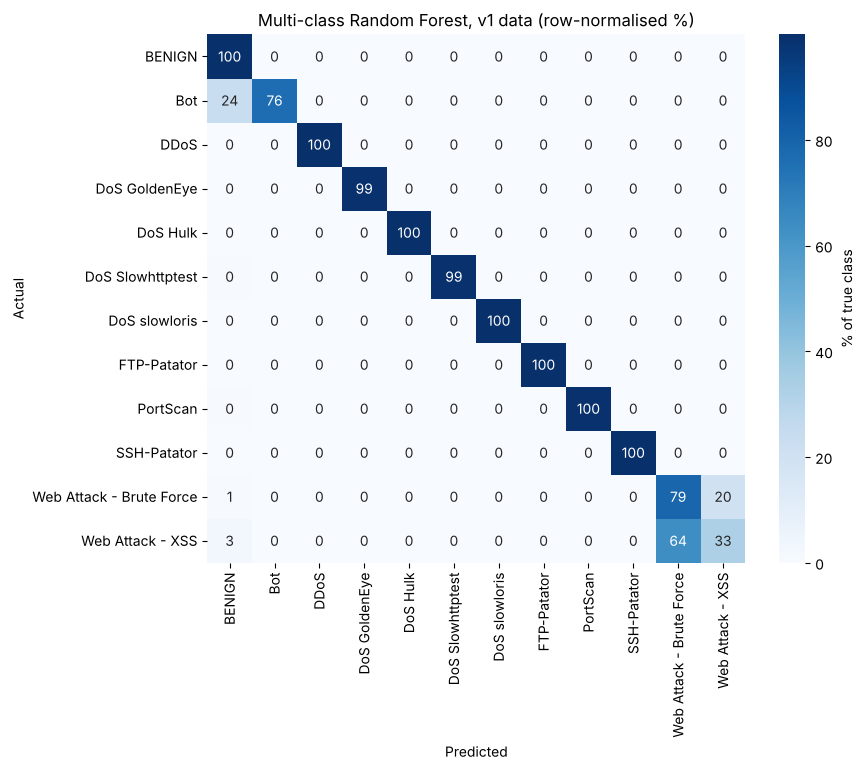

12813

In [7]:
# Multi-class baseline on v1 data (with duplicates)
RARE_V1 = ["Heartbleed", "Infiltration", "Web Attack - Sql Injection"]
v1_mask = ~full_v1["Label"].isin(RARE_V1)
X1, y1 = full_v1.loc[v1_mask, FEATURES], full_v1.loc[v1_mask, "Label"]
X1_tr, X1_te, y1_tr, y1_te = train_test_split(X1, y1, test_size=0.2, random_state=RANDOM_STATE, stratify=y1)
del X1, y1
with timed("rf_multiclass_v1_fit"):
    rf_v1 = make_rf().fit(X1_tr, y1_tr)
pred_v1 = rf_v1.predict(X1_te)
evaluate("multiclass_v1_baseline", y1_te, pred_v1)
plot_confusion("cm_multiclass_v1", y1_te, pred_v1, "Multi-class Random Forest, v1 data (row-normalised %)")
del X1_tr, X1_te, y1_tr, y1_te, rf_v1, pred_v1, full_v1  # v1 is not needed after this section
gc.collect()

## 4. Cleaned data (v2), with web-attack subtypes grouped
Earlier results showed that Web Attack Brute Force / XSS / SQL Injection are confused with each other
(flow features describe traffic *shape*, not HTTP payloads). They are grouped into one `Web Attack` class.
Any class with fewer than `RARE_MIN` flows after cleaning is dropped.

Dropped as too rare: {'Infiltration': 36, 'Heartbleed': 11}


Label
BENIGN              2072147
DoS Hulk             172846
DDoS                 128014
PortScan              90694
DoS GoldenEye         10282
FTP-Patator            5931
DoS slowloris          5374
DoS Slowhttptest       5228
SSH-Patator            3219
Web Attack             2143
Bot                    1948


  [rf_multiclass_v2_grouped_fit] 486.0s



=== multiclass_v2_grouped_web ===


                  precision    recall  f1-score   support

          BENIGN      0.999     0.999     0.999    414430
             Bot      0.883     0.792     0.835       389
            DDoS      1.000     1.000     1.000     25603
   DoS GoldenEye      0.995     0.996     0.995      2056
        DoS Hulk      0.998     0.998     0.998     34569
DoS Slowhttptest      0.988     0.989     0.988      1046
   DoS slowloris      0.994     0.992     0.993      1075
     FTP-Patator      1.000     1.000     1.000      1186
        PortScan      0.989     0.988     0.989     18139
     SSH-Patator      1.000     0.994     0.997       644
      Web Attack      0.993     0.956     0.974       429

        accuracy                          0.998    499566
       macro avg      0.985     0.973     0.979    499566
    weighted avg      0.998     0.998     0.998    499566



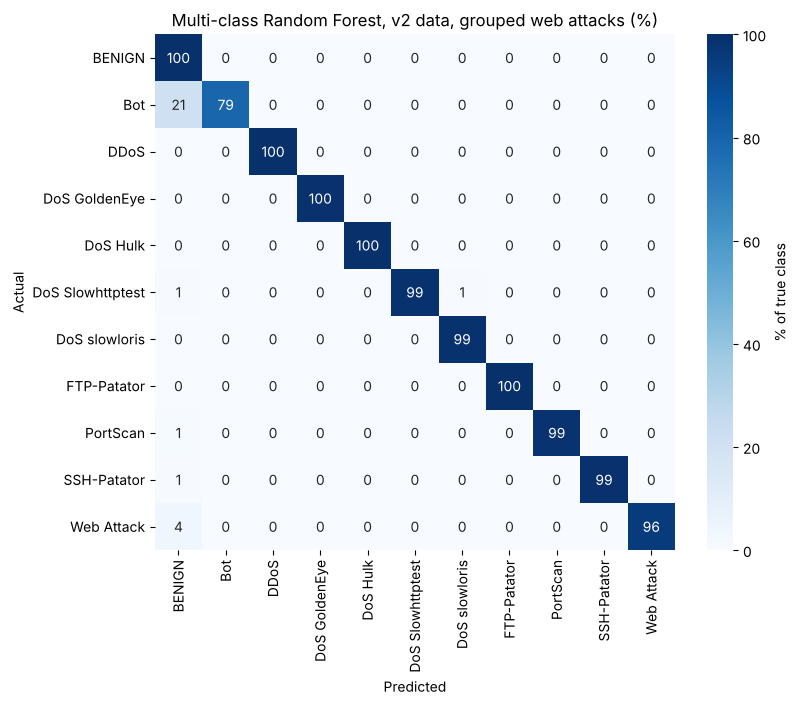

,n_test,accuracy,macro_f1,weighted_f1
multiclass_v1_baseline,565562,0.99864,0.91087,0.99862
multiclass_v2_grouped_web,499566,0.9985,0.97881,0.99849


11481

In [8]:
# v2 multi-class with grouped web attacks
GROUP_MAP = {"Web Attack - Brute Force": "Web Attack", "Web Attack - XSS": "Web Attack", "Web Attack - Sql Injection": "Web Attack"}
y_g_all = full_v2["Label"].replace(GROUP_MAP)
counts = y_g_all.value_counts()
dropped = counts[counts < RARE_MIN].index.tolist()
print("Dropped as too rare:", {c: int(counts[c]) for c in dropped})
RESULTS["data_quality"]["dropped_rare_classes"] = {c: int(counts[c]) for c in dropped}
keep_rows = ~y_g_all.isin(dropped)
X_g = full_v2.loc[keep_rows, FEATURES_V2]
y_g = y_g_all[keep_rows]
print(y_g.value_counts().to_string())

Xg_tr, Xg_te, yg_tr, yg_te = train_test_split(X_g, y_g, test_size=0.2, random_state=RANDOM_STATE, stratify=y_g)
with timed("rf_multiclass_v2_grouped_fit"):
    rf_g = make_rf().fit(Xg_tr, yg_tr)
pred_g = rf_g.predict(Xg_te)
evaluate("multiclass_v2_grouped_web", yg_te, pred_g)
plot_confusion("cm_multiclass_v2_grouped", yg_te, pred_g, "Multi-class Random Forest, v2 data, grouped web attacks (%)")

cmp_full = pd.DataFrame({k: RESULTS["experiments"][k] for k in ("multiclass_v1_baseline", "multiclass_v2_grouped_web")}).T[["n_test", "accuracy", "macro_f1", "weighted_f1"]]
display(cmp_full)
del Xg_tr, Xg_te, yg_tr, yg_te, rf_g, pred_g
gc.collect()

## 5. Imbalance handling and model comparison (benign-capped dataset)
Benign traffic is ~80% of the data. For the comparison experiments, every attack flow is kept and benign
flows are capped at `BENIGN_CAP`. This makes training much faster and softens the imbalance. All models
below use the same split, so the comparison is fair.

In [9]:
# Build the capped dataset and train/test split
Xc, yc = cap_benign(X_g, y_g, BENIGN_CAP)
del X_g, y_g
gc.collect()
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(Xc, yc, test_size=0.2, random_state=RANDOM_STATE, stratify=yc)
print(f"Capped dataset: {len(Xc):,} flows | train {len(Xc_tr):,} | test {len(Xc_te):,}")
print(yc.value_counts().to_string())

Capped dataset: 725,679 flows | train 580,543 | test 145,136
Label
BENIGN              300000
DoS Hulk            172846
DDoS                128014
PortScan             90694
DoS GoldenEye        10282
FTP-Patator           5931
DoS slowloris         5374
DoS Slowhttptest      5228
SSH-Patator           3219
Web Attack            2143
Bot                   1948


In [10]:
# Imbalance strategies with Random Forest: plain, class weights, SMOTE
with timed("rf_capped_plain_fit"):
    rf_plain = make_rf().fit(Xc_tr, yc_tr)
pred_plain = rf_plain.predict(Xc_te)
evaluate("capped_rf_plain", yc_te, pred_plain, show_report=False)

with timed("rf_capped_balanced_fit"):
    rf_bal = make_rf(class_weight="balanced_subsample").fit(Xc_tr, yc_tr)
evaluate("capped_rf_class_weight", yc_te, rf_bal.predict(Xc_te), show_report=False)

if SMOTE is not None:
    class_counts = yc_tr.value_counts()
    strategy = {c: SMOTE_TARGET for c, n in class_counts.items() if c != "BENIGN" and n < SMOTE_TARGET}
    print("SMOTE targets:", {c: f"{int(class_counts[c])} -> {n}" for c, n in strategy.items()})
    with timed("smote_resample"):
        Xs_tr, ys_tr = SMOTE(sampling_strategy=strategy, k_neighbors=5, random_state=RANDOM_STATE).fit_resample(Xc_tr, yc_tr)
    with timed("rf_capped_smote_fit"):
        rf_smote = make_rf().fit(Xs_tr, ys_tr)
    evaluate("capped_rf_smote", yc_te, rf_smote.predict(Xc_te), show_report=False)
    del Xs_tr, ys_tr, rf_smote
else:
    print("imbalanced-learn not installed: skipping SMOTE (pip install imbalanced-learn)")
del rf_bal
gc.collect()

  [rf_capped_plain_fit] 81.6s


  [rf_capped_balanced_fit] 85.8s


SMOTE targets: {'FTP-Patator': '4745 -> 5000', 'DoS slowloris': '4299 -> 5000', 'DoS Slowhttptest': '4182 -> 5000', 'SSH-Patator': '2575 -> 5000', 'Web Attack': '1714 -> 5000', 'Bot': '1559 -> 5000'}


  [smote_resample] 2.8s


  [rf_capped_smote_fit] 80.4s


48

,accuracy,macro_f1,weighted_f1,macro_recall
capped_decision_tree,0.99824,0.98799,0.99824,0.98666
capped_random_forest,0.99842,0.98937,0.99841,0.98674
capped_hist_gradient_boosting,0.9968,0.9707,0.99685,0.97854
capped_rf_class_weight,0.99856,0.99021,0.99856,0.98787
capped_rf_smote,0.99852,0.99003,0.99852,0.98858


,model,fit_seconds,predict_us_per_flow
0,decision_tree,23.9,0.2
1,random_forest,81.6,5.5
2,hist_gradient_boosting,14.8,3.1


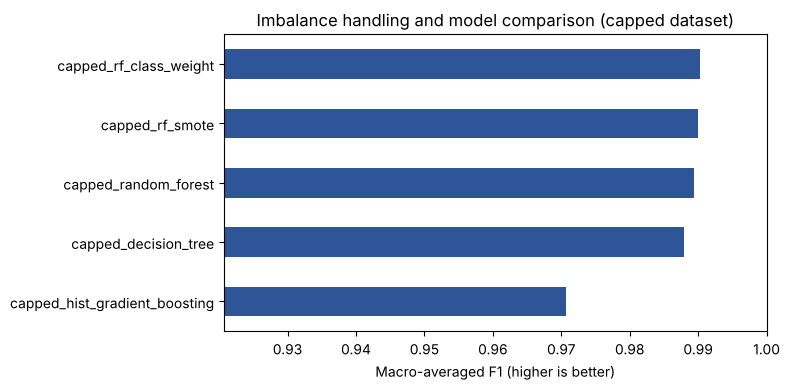

In [11]:
# Model comparison: Decision Tree vs Random Forest vs Gradient Boosting
models = {
    "decision_tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "random_forest": None,  # reuse rf_plain
    "hist_gradient_boosting": HistGradientBoostingClassifier(max_iter=100, random_state=RANDOM_STATE),
}
speed_rows = []
for model_name, model in models.items():
    if model is None:
        fitted, fit_s = rf_plain, RESULTS["timings"]["rf_capped_plain_fit"]
    else:
        t0 = time.perf_counter()
        fitted = model.fit(Xc_tr, yc_tr)
        fit_s = time.perf_counter() - t0
        RESULTS["timings"][f"{model_name}_capped_fit"] = round(fit_s, 2)
    t0 = time.perf_counter()
    pred = fitted.predict(Xc_te)
    predict_s = time.perf_counter() - t0
    evaluate(f"capped_{model_name}", yc_te, pred, show_report=False)
    speed_rows.append({"model": model_name, "fit_seconds": round(fit_s, 1), "predict_us_per_flow": round(1e6 * predict_s / len(Xc_te), 1)})

summary_keys = [k for k in ["capped_decision_tree", "capped_random_forest", "capped_hist_gradient_boosting", "capped_rf_class_weight", "capped_rf_smote"] if k in RESULTS["experiments"]]
comparison = pd.DataFrame({k: RESULTS["experiments"][k] for k in summary_keys}).T[["accuracy", "macro_f1", "weighted_f1", "macro_recall"]]
display(comparison)
display(pd.DataFrame(speed_rows))
comparison.to_csv(OUT_DIR / "model_comparison.csv")
pd.DataFrame(speed_rows).to_csv(OUT_DIR / "model_speed.csv", index=False)

plt.figure(figsize=(8, 4))
comparison["macro_f1"].sort_values().plot.barh(color="#2E5597")
plt.xlabel("Macro-averaged F1 (higher is better)")
plt.title("Imbalance handling and model comparison (capped dataset)")
plt.xlim(max(0, comparison["macro_f1"].min() - 0.05), 1.0)
save_fig("model_comparison_macro_f1")

## 6. Cross-day validation
The first DDoS result was almost perfect, which can mean the model learned *which day* a flow came from
rather than what an attack looks like. Test: train with benign traffic from one day and test on benign
traffic from a **different** day. A model that generalises should keep a low false-positive rate there.
The "same-day" control holds out benign flows from the training day.

In [12]:
# Cross-day check
def cross_day(attack_label, attack_source, benign_train_day, benign_test_day, cap=100_000):
    atk = full_v2[(full_v2["Source"] == attack_source) & (full_v2["Label"] == attack_label)]
    ben_tr_pool = full_v2[(full_v2["Source"] == benign_train_day) & (full_v2["Label"] == "BENIGN")]
    ben_other = full_v2[(full_v2["Source"] == benign_test_day) & (full_v2["Label"] == "BENIGN")]
    cap = min(cap, len(ben_tr_pool), len(ben_other))
    atk_tr, atk_te = train_test_split(atk, test_size=0.2, random_state=RANDOM_STATE)
    ben_tr_pool = ben_tr_pool.sample(min(2 * cap, len(ben_tr_pool)), random_state=RANDOM_STATE)
    ben_tr, ben_same = train_test_split(ben_tr_pool, test_size=0.5, random_state=RANDOM_STATE)
    ben_other = ben_other.sample(cap, random_state=RANDOM_STATE)
    train = pd.concat([atk_tr, ben_tr])
    clf = make_rf().fit(train[FEATURES_V2], train["Label"] == attack_label)
    fp_flows = ben_other[FEATURES_V2][clf.predict(ben_other[FEATURES_V2])]
    row = {
        "attack": attack_label,
        "benign_train_day": benign_train_day,
        "benign_test_day": benign_test_day,
        "attack_recall": round(float(clf.predict(atk_te[FEATURES_V2]).mean()), 4),
        "false_positive_rate_same_day": round(float(clf.predict(ben_same[FEATURES_V2]).mean()), 4),
        "false_positive_rate_other_day": round(float(len(fp_flows) / len(ben_other)), 4),
        "top_false_positive_ports": {int(p): int(n) for p, n in fp_flows["Destination Port"].value_counts().head(3).items()},
    }
    return row


with timed("cross_day_validation"):
    cross_rows = [
        cross_day("DDoS", "Fri-PM-DDoS", "Tuesday", "Monday"),
        cross_day("DDoS", "Fri-PM-DDoS", "Monday", "Tuesday"),
        cross_day("PortScan", "Fri-PM-PortScan", "Tuesday", "Monday"),
        cross_day("PortScan", "Fri-PM-PortScan", "Monday", "Tuesday"),
    ]
cross_df = pd.DataFrame(cross_rows)
display(cross_df)
del full_v2  # no longer needed
gc.collect()
cross_df.to_csv(OUT_DIR / "cross_day_validation.csv", index=False)
RESULTS["cross_day"] = cross_rows

  [cross_day_validation] 43.9s


,attack,benign_train_day,benign_test_day,attack_recall,false_positive_rate_same_day,false_positive_rate_other_day,top_false_positive_ports
0,DDoS,Tuesday,Monday,1.0000,0.0,0.1055,"{443: 2122, 80: 1373, 22: 57}"
1,DDoS,Monday,Tuesday,0.9995,0.0,0.0000,{}
2,PortScan,Tuesday,Monday,0.9999,0.0,0.0019,"{80: 110, 443: 78, 57316: 1}"
3,PortScan,Monday,Tuesday,0.9999,0.0,0.0001,"{3268: 2, 80: 2, 21: 1}"


## 7. Final model, feature importance
The final detector is the capped-dataset Random Forest. Feature importance gives a first, global view of
what the model relies on (SHAP in section 9 gives per-alert explanations).

Saved model to models/xnids_rf_capped.joblib (8 MB, git-ignored)


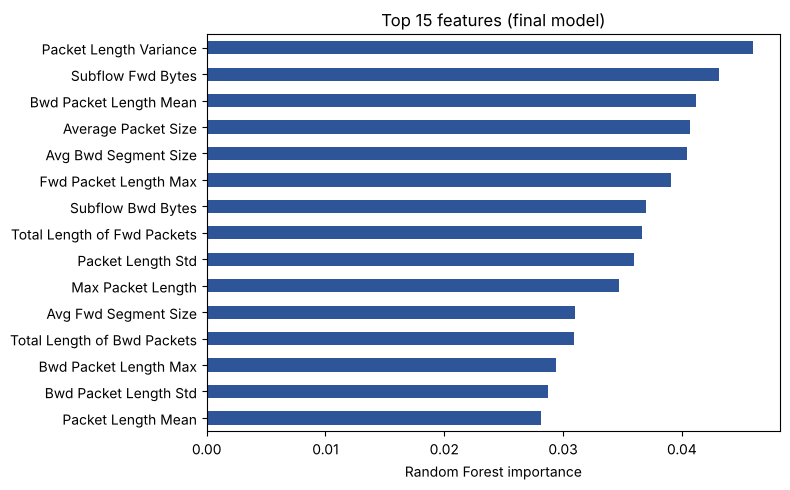

Packet Length Variance         0.0460
Subflow Fwd Bytes              0.0431
Bwd Packet Length Mean         0.0412
Average Packet Size            0.0407
Avg Bwd Segment Size           0.0404
Fwd Packet Length Max          0.0391
Subflow Bwd Bytes              0.0370
Total Length of Fwd Packets    0.0367
Packet Length Std              0.0360
Max Packet Length              0.0347
Avg Fwd Segment Size           0.0310
Total Length of Bwd Packets    0.0309
Bwd Packet Length Max          0.0294
Bwd Packet Length Std          0.0287
Packet Length Mean             0.0281


In [13]:
# Final model and feature importance
rf_final = rf_plain
joblib_path = MODEL_DIR / "xnids_rf_capped.joblib"
try:
    import joblib

    joblib.dump(rf_final, joblib_path, compress=3)
    print(f"Saved model to {joblib_path} ({joblib_path.stat().st_size / 1e6:.0f} MB, git-ignored)")
except Exception as exc:  # saving is a convenience, never fatal
    print("Could not save model:", exc)

imp = pd.Series(rf_final.feature_importances_, index=Xc_tr.columns).nlargest(15)
plt.figure(figsize=(8, 5))
imp.sort_values().plot.barh(color="#2E5597")
plt.xlabel("Random Forest importance")
plt.title("Top 15 features (final model)")
save_fig("feature_importance_top15")
print(imp.round(4).to_string())

## 8. Risk-based alert prioritisation
Every flow the model flags as an attack gets a **priority score from 0 to 100**, modelled on a classic
risk matrix (likelihood x impact):

`score = 100 x confidence x (w_sev x severity/5 + w_crit x criticality/5)`

- **confidence** (likelihood): the model's predicted probability for the flagged class. Because it multiplies
  everything else, a low-confidence alert is pushed down no matter how severe the attack class is.
- **severity** (1-5): how damaging the attack class is. A documented judgement call, see `SEVERITY`.
- **criticality** (1-5): how important the targeted *service* is, derived from the destination port.
  The ML-ready CICIDS2017 CSVs have no IP addresses, so service criticality stands in for asset criticality.

Tiers: Critical >= 80, High >= 60, Medium >= 40, Low below that. An earlier additive version
(`0.4 conf + 0.4 sev + 0.2 crit`) put about 75% of alerts in Critical, because almost every alert has
confidence near 1, so it did not help an analyst decide what to look at first. The weights are a design
choice, so the next cell also measures how much the ranking changes under different weights.

85,128 alerts raised from 145,136 test flows


,alerts,precision
tier,,
Critical,26334,0.999848
High,40381,0.999257
Medium,707,0.977369
Low,17706,0.997515


,test_row,true_label,predicted,confidence,dest_port,severity,criticality,priority,tier,is_true_attack
0,53505,SSH-Patator,SSH-Patator,1.0,22,4,5.0,88.0,Critical,True
1,117314,SSH-Patator,SSH-Patator,1.0,22,4,5.0,88.0,Critical,True
2,56830,SSH-Patator,SSH-Patator,1.0,22,4,5.0,88.0,Critical,True
3,53517,SSH-Patator,SSH-Patator,1.0,22,4,5.0,88.0,Critical,True
4,70784,SSH-Patator,SSH-Patator,1.0,22,4,5.0,88.0,Critical,True
5,135264,SSH-Patator,SSH-Patator,1.0,22,4,5.0,88.0,Critical,True
6,134874,SSH-Patator,SSH-Patator,1.0,22,4,5.0,88.0,Critical,True
7,101431,SSH-Patator,SSH-Patator,1.0,22,4,5.0,88.0,Critical,True
8,119558,SSH-Patator,SSH-Patator,1.0,22,4,5.0,88.0,Critical,True
9,97797,SSH-Patator,SSH-Patator,1.0,22,4,5.0,88.0,Critical,True


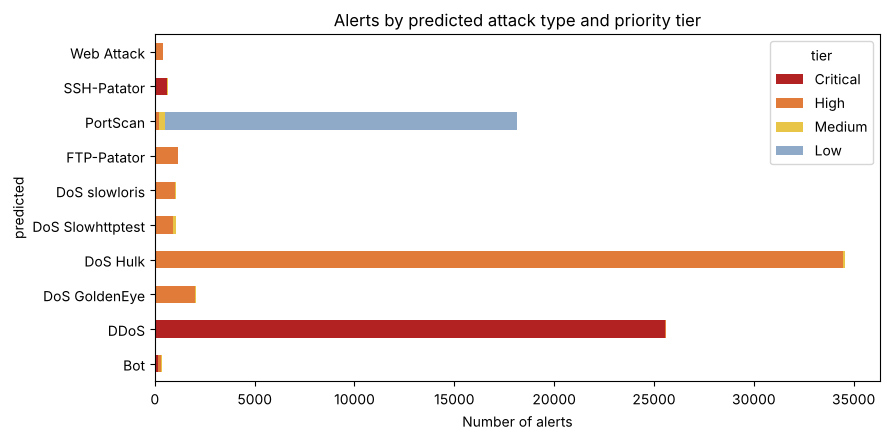

In [14]:
# Score and tier the alerts
SEVERITY = {
    "DDoS": 5, "Bot": 5, "DoS Hulk": 4, "DoS GoldenEye": 4, "SSH-Patator": 4, "Web Attack": 4,
    "DoS slowloris": 3, "DoS Slowhttptest": 3, "FTP-Patator": 3, "PortScan": 2,
}
PORT_CRITICALITY = {
    22: 5, 3389: 5, 445: 5, 389: 5, 88: 5, 3306: 5, 1433: 5, 5432: 5, 1521: 5, 139: 4, 23: 4, 443: 4, 53: 4,
    21: 3, 80: 3, 8080: 3, 25: 3, 110: 3, 143: 3, 123: 2, 137: 2, 138: 2, 67: 2, 68: 2,
}
W_SEVERITY, W_CRITICALITY = 0.6, 0.4  # impact = 0.6 x severity + 0.4 x service criticality (both scaled to 0-1)
TIERS = [(80, "Critical"), (60, "High"), (40, "Medium"), (0, "Low")]


def priority_score(confidence, severity, criticality, w_sev=W_SEVERITY, w_crit=W_CRITICALITY):
    return 100 * confidence * (w_sev * severity / 5 + w_crit * criticality / 5)


def tier_of(score):
    return next(name for cutoff, name in TIERS if score >= cutoff)


proba = rf_final.predict_proba(Xc_te)
classes = rf_final.classes_
pred_idx = proba.argmax(axis=1)
pred_label = classes[pred_idx]
flagged = pred_label != "BENIGN"

alerts = pd.DataFrame({
    "test_row": np.flatnonzero(flagged),
    "true_label": yc_te.to_numpy()[flagged],
    "predicted": pred_label[flagged],
    "confidence": proba.max(axis=1)[flagged],
    "dest_port": Xc_te["Destination Port"].to_numpy()[flagged].astype(int),
})
alerts["severity"] = alerts["predicted"].map(SEVERITY).fillna(3)
alerts["criticality"] = alerts["dest_port"].map(PORT_CRITICALITY).fillna(1)
alerts["priority"] = priority_score(alerts["confidence"], alerts["severity"], alerts["criticality"]).round(1)
alerts["tier"] = alerts["priority"].map(tier_of)
alerts["is_true_attack"] = alerts["true_label"] != "BENIGN"
alerts = alerts.sort_values("priority", ascending=False).reset_index(drop=True)

print(f"{len(alerts):,} alerts raised from {len(Xc_te):,} test flows")
tier_order = ["Critical", "High", "Medium", "Low"]
tier_table = alerts.groupby("tier").agg(alerts=("priority", "size"), precision=("is_true_attack", "mean")).reindex(tier_order).fillna(0)
display(tier_table)
display(alerts.head(10))
alerts.head(500).to_csv(OUT_DIR / "top_alerts.csv", index=False)

plt.figure(figsize=(9, 4.5))
tier_by_class = alerts.groupby(["predicted", "tier"]).size().unstack(fill_value=0).reindex(columns=tier_order, fill_value=0)
tier_by_class.plot.barh(stacked=True, color=["#B22222", "#E07B39", "#E8C547", "#8FA9C9"], ax=plt.gca())
plt.xlabel("Number of alerts")
plt.title("Alerts by predicted attack type and priority tier")
save_fig("alerts_by_class_and_tier")

In [15]:
# Sensitivity analysis: how much does the ranking change if the weights change?
weight_sets = {
    "default 0.6 sev / 0.4 crit": (0.6, 0.4),
    "equal 0.5 / 0.5": (0.5, 0.5),
    "severity-heavy 0.8 / 0.2": (0.8, 0.2),
    "criticality-heavy 0.3 / 0.7": (0.3, 0.7),
}
score_table = pd.DataFrame({k: priority_score(alerts["confidence"], alerts["severity"], alerts["criticality"], *w) for k, w in weight_sets.items()})
rank_corr_weights = score_table.rank().corr(method="spearman").round(3)
display(rank_corr_weights)
rank_corr_weights.to_csv(OUT_DIR / "weight_sensitivity_spearman.csv")
# how different is the priority ranking from simply sorting by model confidence?
vs_confidence = round(float(score_table["default 0.6 sev / 0.4 crit"].rank().corr(alerts["confidence"].rank(), method="spearman")), 3)
print("Spearman rank correlation, priority vs. confidence-only ranking:", vs_confidence)
RESULTS["prioritisation"] = {
    "alerts": int(len(alerts)),
    "tier_counts": {t: int(n) for t, n in alerts["tier"].value_counts().items()},
    "tier_precision": {t: round(float(v), 4) for t, v in tier_table["precision"].items()},
    "min_spearman_across_weight_sets": float(rank_corr_weights.to_numpy().min()),
    "spearman_priority_vs_confidence_only": vs_confidence,
}

,default 0.6 sev / 0.4 crit,equal 0.5 / 0.5,severity-heavy 0.8 / 0.2,criticality-heavy 0.3 / 0.7
default 0.6 sev / 0.4 crit,1.000,0.999,0.994,0.988
equal 0.5 / 0.5,0.999,1.000,0.992,0.993
severity-heavy 0.8 / 0.2,0.994,0.992,1.000,0.980
criticality-heavy 0.3 / 0.7,0.988,0.993,0.980,1.000


Spearman rank correlation, priority vs. confidence-only ranking: 0.122


## 9. SHAP explanations
SHAP assigns each feature a contribution to one prediction. Exact SHAP on a 100-tree forest grown on
hundreds of thousands of flows is expensive, so this section uses a **compact explanation model**
(shallower forest) and explains only a **sample of flagged alerts**. That matches how an analyst would use it:
explanations are needed for alerts, not for every benign flow.

In [16]:
# Train the compact explanation model
SHAP_PER_CLASS = 12 if FAST else 40  # flagged flows explained per predicted class
with timed("rf_explain_model_fit"):
    rf_explain = RandomForestClassifier(n_estimators=40 if FAST else 60, max_depth=14, min_samples_leaf=3, random_state=RANDOM_STATE, n_jobs=-1).fit(Xc_tr, yc_tr)
pred_explain = rf_explain.predict(Xc_te)
evaluate("capped_rf_explain_model", yc_te, pred_explain, show_report=False)
print("Explanation model macro-F1:", RESULTS["experiments"]["capped_rf_explain_model"]["macro_f1"], "| main model:", RESULTS["experiments"]["capped_rf_plain"]["macro_f1"])

  [rf_explain_model_fit] 43.8s


Explanation model macro-F1: 0.9713 | main model: 0.98937


In [17]:
# Compute SHAP values for a sample of flagged alerts
def class_shap(values, class_index_per_row):
    """Return each row's SHAP vector for its own predicted class (handles old/new SHAP output shapes)."""
    arr = np.stack(values, axis=-1) if isinstance(values, list) else np.asarray(values)  # (rows, features, classes)
    return arr[np.arange(arr.shape[0]), :, class_index_per_row]


if shap is None:
    print("shap is not installed (pip install shap): skipping SHAP section")
else:
    expl_classes = list(rf_explain.classes_)
    expl_proba = rf_explain.predict_proba(Xc_te)
    expl_pred = np.array(expl_classes)[expl_proba.argmax(axis=1)]
    flagged_rows = np.flatnonzero(expl_pred != "BENIGN")
    rng = np.random.default_rng(RANDOM_STATE)
    sample_rows = np.concatenate([
        rng.choice(g, size=min(SHAP_PER_CLASS, len(g)), replace=False)
        for _, g in pd.Series(flagged_rows).groupby(expl_pred[flagged_rows]) if len(g)
    ]) if len(flagged_rows) else np.array([], dtype=int)
    X_shap = Xc_te.iloc[sample_rows]
    shap_pred_idx = expl_proba[sample_rows].argmax(axis=1)
    with timed("shap_values"):
        explainer = shap.TreeExplainer(rf_explain)
        raw_values = explainer.shap_values(X_shap, check_additivity=False)
    sv = class_shap(raw_values, shap_pred_idx)  # (rows, features)
    print(f"SHAP computed for {len(X_shap)} flagged flows x {X_shap.shape[1]} features")

  [shap_values] 7.9s
SHAP computed for 400 flagged flows x 77 features


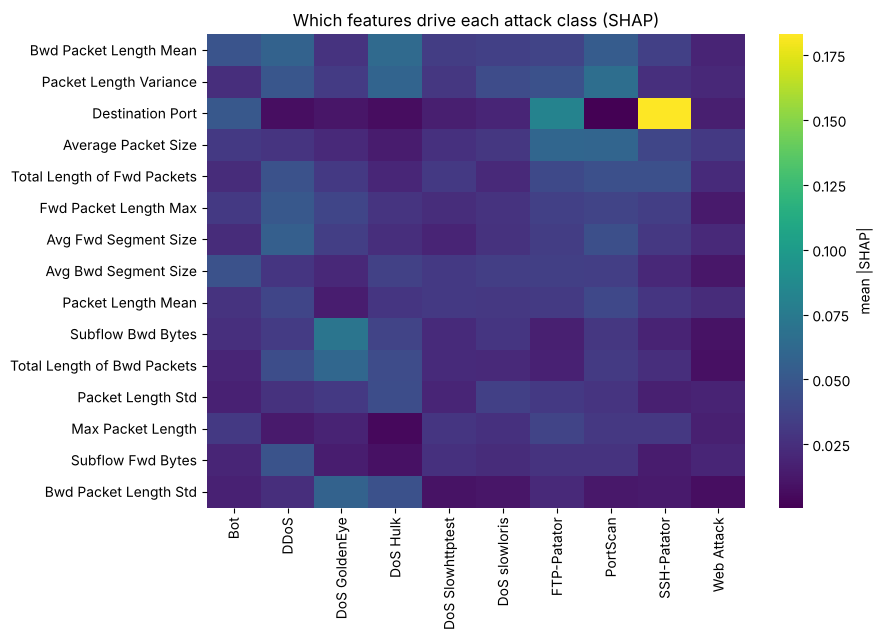

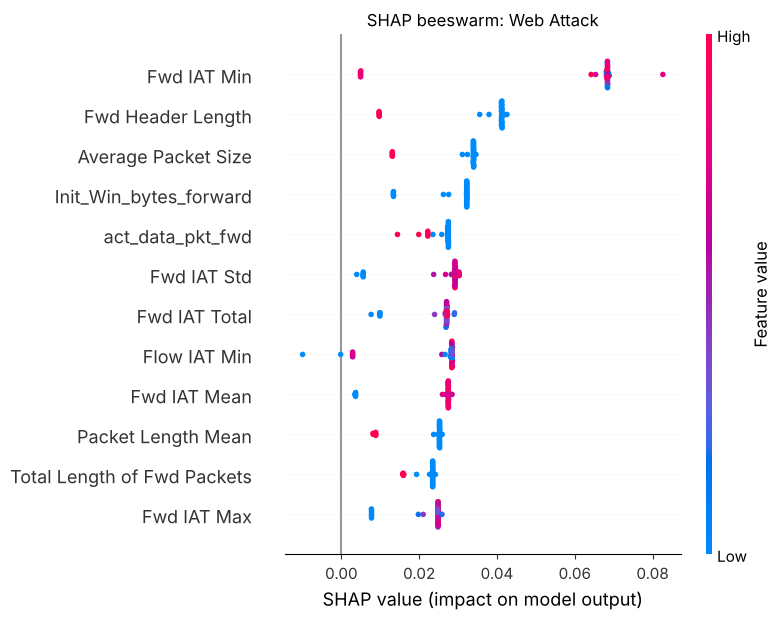

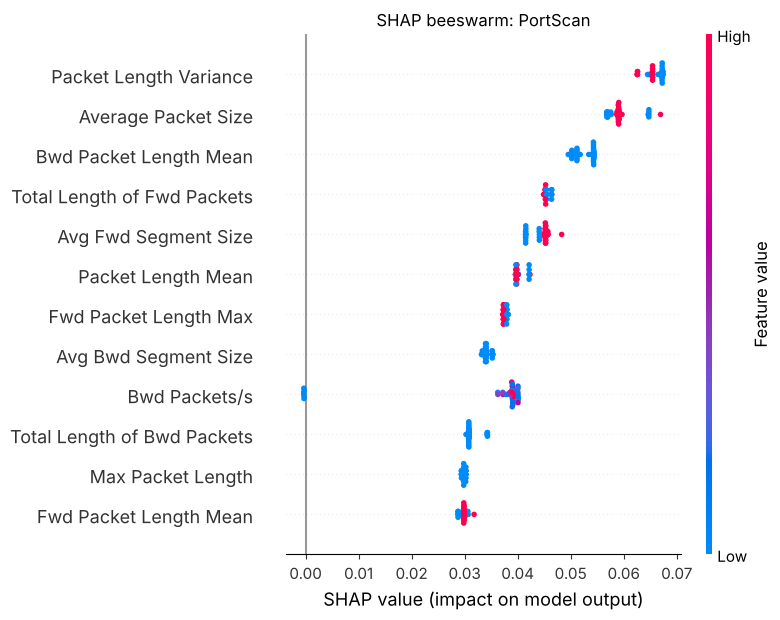

In [18]:
# SHAP figures: per-class heatmap, beeswarm, waterfall of the top alert
if shap is not None and len(X_shap):
    shap_pred_label = np.array(expl_classes)[shap_pred_idx]
    class_matrix = pd.DataFrame(
        {c: np.abs(sv[shap_pred_label == c]).mean(axis=0) for c in sorted(set(shap_pred_label))}, index=X_shap.columns
    )
    top_features = class_matrix.sum(axis=1).nlargest(15).index
    plt.figure(figsize=(9, 6.5))
    sns.heatmap(class_matrix.loc[top_features], cmap="viridis", cbar_kws={"label": "mean |SHAP|"})
    plt.title("Which features drive each attack class (SHAP)")
    save_fig("shap_class_feature_heatmap")

    for cls in ("Web Attack", "PortScan"):
        rows = shap_pred_label == cls
        if rows.sum() >= 5:
            try:
                shap.summary_plot(sv[rows], X_shap[rows], show=False, max_display=12)
                plt.title(f"SHAP beeswarm: {cls}")
                save_fig(f"shap_beeswarm_{cls.replace(' ', '_').lower()}")
            except Exception as exc:
                print(f"beeswarm for {cls} skipped:", exc)

,priority,tier,predicted,confidence,dest_port,explainer_agrees,explanation
0,88.0,Critical,SSH-Patator,1.0,22,True,Flagged as SSH-Patator (100% confidence). Main drivers: Destination Port = 22 (raises SSH-Patator likelihood); Bwd Header Length = 1032 (raises SSH-Patator likelihood); Subflow Bwd Packets = 32 (r...
1,88.0,Critical,SSH-Patator,1.0,22,True,Flagged as SSH-Patator (100% confidence). Main drivers: Destination Port = 22 (raises SSH-Patator likelihood); Bwd Header Length = 1064 (raises SSH-Patator likelihood); Subflow Bwd Packets = 33 (r...
2,88.0,Critical,SSH-Patator,1.0,22,True,Flagged as SSH-Patator (100% confidence). Main drivers: Destination Port = 22 (raises SSH-Patator likelihood); Bwd Header Length = 1032 (raises SSH-Patator likelihood); Subflow Bwd Packets = 32 (r...
3,88.0,Critical,SSH-Patator,1.0,22,True,Flagged as SSH-Patator (100% confidence). Main drivers: Destination Port = 22 (raises SSH-Patator likelihood); Bwd Header Length = 1032 (raises SSH-Patator likelihood); Subflow Bwd Packets = 32 (r...
4,88.0,Critical,SSH-Patator,1.0,22,True,Flagged as SSH-Patator (100% confidence). Main drivers: Destination Port = 22 (raises SSH-Patator likelihood); Bwd Header Length = 1032 (raises SSH-Patator likelihood); Subflow Bwd Packets = 32 (r...
5,88.0,Critical,SSH-Patator,1.0,22,True,Flagged as SSH-Patator (100% confidence). Main drivers: Destination Port = 22 (raises SSH-Patator likelihood); Bwd Header Length = 1032 (raises SSH-Patator likelihood); Subflow Bwd Packets = 32 (r...
6,88.0,Critical,SSH-Patator,1.0,22,True,Flagged as SSH-Patator (100% confidence). Main drivers: Destination Port = 22 (raises SSH-Patator likelihood); Bwd Header Length = 1032 (raises SSH-Patator likelihood); Subflow Bwd Packets = 32 (r...
7,88.0,Critical,SSH-Patator,1.0,22,True,Flagged as SSH-Patator (100% confidence). Main drivers: Destination Port = 22 (raises SSH-Patator likelihood); Bwd Header Length = 1064 (raises SSH-Patator likelihood); Subflow Bwd Packets = 33 (r...
8,88.0,Critical,SSH-Patator,1.0,22,True,Flagged as SSH-Patator (100% confidence). Main drivers: Destination Port = 22 (raises SSH-Patator likelihood); Bwd Header Length = 1064 (raises SSH-Patator likelihood); Subflow Bwd Packets = 33 (r...
9,88.0,Critical,SSH-Patator,1.0,22,True,Flagged as SSH-Patator (100% confidence). Main drivers: Destination Port = 22 (raises SSH-Patator likelihood); Bwd Header Length = 1032 (raises SSH-Patator likelihood); Subflow Bwd Packets = 32 (r...


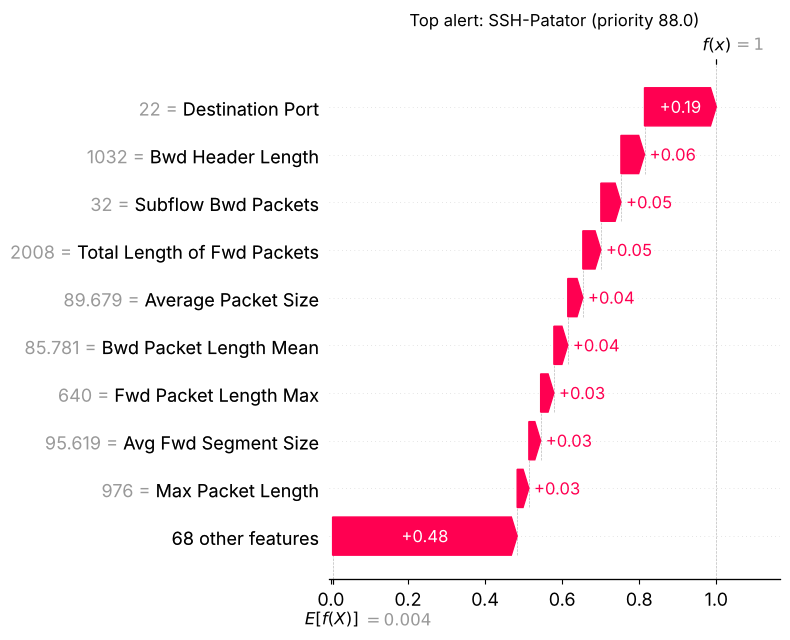

In [19]:
# Plain-language explanations for the highest-priority alerts
def explain_alert(x_row, shap_row, predicted, confidence, k=3):
    """Turn one alert's top-k SHAP drivers into a sentence an analyst can read."""
    order = np.argsort(-np.abs(shap_row))[:k]
    drivers = [f"{x_row.index[i]} = {x_row.iloc[i]:.4g} ({'raises' if shap_row[i] > 0 else 'lowers'} {predicted} likelihood)" for i in order]
    return f"Flagged as {predicted} ({confidence:.0%} confidence). Main drivers: " + "; ".join(drivers) + "."


if shap is not None:
    top = alerts.head(10)
    top_rows = top["test_row"].to_numpy()
    # explain the class the alert was actually raised for (by the main model)
    top_idx = np.array([expl_classes.index(c) for c in top["predicted"]])
    top_sv = class_shap(explainer.shap_values(Xc_te.iloc[top_rows], check_additivity=False), top_idx)
    top = top.assign(
        explainer_agrees=np.array(expl_classes)[expl_proba[top_rows].argmax(axis=1)] == top["predicted"].to_numpy(),
        explanation=[
            explain_alert(Xc_te.iloc[r], top_sv[i], top["predicted"].iloc[i], top["confidence"].iloc[i])
            for i, r in enumerate(top_rows)
        ],
    )
    top.to_csv(OUT_DIR / "top_alerts_explained.csv", index=False)
    pd.set_option("display.max_colwidth", 200)
    display(top[["priority", "tier", "predicted", "confidence", "dest_port", "explainer_agrees", "explanation"]])
    try:
        ev = explainer.expected_value
        base = float(np.atleast_1d(ev)[top_idx[0]])
        shap.plots.waterfall(
            shap.Explanation(values=top_sv[0], base_values=base, data=Xc_te.iloc[top_rows[0]].to_numpy(), feature_names=list(Xc_te.columns)),
            max_display=10, show=False,
        )
        plt.title(f"Top alert: {expl_classes[top_idx[0]]} (priority {top.iloc[0]['priority']})")
        save_fig("shap_waterfall_top_alert")
    except Exception as exc:
        print("waterfall skipped:", exc)

## 10. Save results

In [20]:
# Save metrics and run information
RESULTS["environment"] = {
    "python": platform.python_version(),
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "scikit_learn": sklearn.__version__,
    "shap": getattr(shap, "__version__", None),
    "cpu_count": os.cpu_count(),
}
with open(OUT_DIR / "metrics.json", "w") as fh:
    json.dump(RESULTS, fh, indent=2, default=str)

all_exp = pd.DataFrame({k: {m: v[m] for m in ("n_test", "accuracy", "macro_f1", "weighted_f1", "macro_recall")} for k, v in RESULTS["experiments"].items()}).T
display(all_exp)
all_exp.to_csv(OUT_DIR / "experiment_summary.csv")
print("Timings (s):", json.dumps(RESULTS["timings"], indent=1))
print(f"Saved results to {OUT_DIR}")

,n_test,accuracy,macro_f1,weighted_f1,macro_recall
binary_benign_vs_ddos,151039.0,0.99996,0.99993,0.99996,0.99993
multiclass_v1_baseline,565562.0,0.99864,0.91087,0.99862,0.90499
multiclass_v2_grouped_web,499566.0,0.99850,0.97881,0.99849,0.97288
capped_rf_plain,145136.0,0.99842,0.98937,0.99841,0.98674
capped_rf_class_weight,145136.0,0.99856,0.99021,0.99856,0.98787
capped_rf_smote,145136.0,0.99852,0.99003,0.99852,0.98858
capped_decision_tree,145136.0,0.99824,0.98799,0.99824,0.98666
capped_random_forest,145136.0,0.99842,0.98937,0.99841,0.98674
capped_hist_gradient_boosting,145136.0,0.99680,0.97070,0.99685,0.97854
capped_rf_explain_model,145136.0,0.99735,0.97130,0.99727,0.95630


Timings (s): {
 "load_and_clean": 30.92,
 "rf_binary_fit": 54.25,
 "rf_multiclass_v1_fit": 526.59,
 "rf_multiclass_v2_grouped_fit": 485.97,
 "rf_capped_plain_fit": 81.6,
 "rf_capped_balanced_fit": 85.79,
 "smote_resample": 2.75,
 "rf_capped_smote_fit": 80.43,
 "decision_tree_capped_fit": 23.87,
 "hist_gradient_boosting_capped_fit": 14.76,
 "cross_day_validation": 43.87,
 "rf_explain_model_fit": 43.79,
 "shap_values": 7.9
}
Saved results to reports
